##### imports

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import shutil
import random

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score,precision_score,f1_score,recall_score

#### Data Loading

In [6]:
ls

archive/                       oc50k_EDA.ipynb
archive.zip                    reports/
oc_risk50k_single_dataset.csv


In [71]:
og_df = pd.read_csv("oc_risk50k_single_dataset.csv")
df= og_df.copy()
print(df.shape,"\n\n")
df.head(5)

(50000, 52) 




,Patient_ID,Age,Menopausal_Status,Age_At_Menarche,Age_At_Menopause,Family_History,BRCA1_Status,BRCA2_Status,Lynch_Syndrome_Status,BMI,...,Charlson_Comorbidity_Index,ECOG_Performance_Status,Creatinine,Liver_Enzyme_Level,Treatment_Status,Time_To_Progression,Follow_Up_Status,Partition,Ovarian_Cancer_Status,Risk_Category
0,PAT_00001,53.8,1,11.0,48.6,0,0,0,0,34.5,...,1,2,0.98,30.6,0,-1.0,2,Train,0,0
1,PAT_00002,66.8,1,13.2,50.4,1,0,0,0,18.5,...,1,1,1.01,33.7,3,25.1,0,Train,1,1
2,PAT_00003,51.9,1,13.2,50.9,1,0,0,0,23.2,...,0,2,0.73,17.8,2,5.5,0,Train,1,2
3,PAT_00004,67.6,1,12.3,51.1,0,0,0,0,24.7,...,2,1,1.01,25.3,2,70.0,0,Test,1,2
4,PAT_00005,80.5,1,14.9,52.1,1,0,0,0,22.0,...,0,0,0.85,30.1,0,-1.0,1,Test,0,0


In [73]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 52 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Patient_ID                         50000 non-null  str    
 1   Age                                50000 non-null  float64
 2   Menopausal_Status                  50000 non-null  int64  
 3   Age_At_Menarche                    50000 non-null  float64
 4   Age_At_Menopause                   50000 non-null  float64
 5   Family_History                     50000 non-null  int64  
 6   BRCA1_Status                       50000 non-null  int64  
 7   BRCA2_Status                       50000 non-null  int64  
 8   Lynch_Syndrome_Status              50000 non-null  int64  
 9   BMI                                50000 non-null  float64
 10  Parity                             50000 non-null  int64  
 11  Oral_Contraceptive_History         50000 non-null  int64  
 12  O

^^ some columns have nulls

In [75]:
df.Ovarian_Cancer_Status.value_counts()

Ovarian_Cancer_Status
0    25000
1    25000
Name: count, dtype: int64

Equal class distribution

In [78]:
# remove non-predictors + sources of data leakage
cols_removed = ["Patient_ID","Risk_Category",
                "Follow_Up_Status",
                "Treatment_Status",
                "Time_To_Progression"] 

df = df.drop(labels=cols_removed,axis=1)
df.shape

(50000, 47)

In [80]:
modelling_cols = list(df.columns)
modelling_cols.remove("Partition")

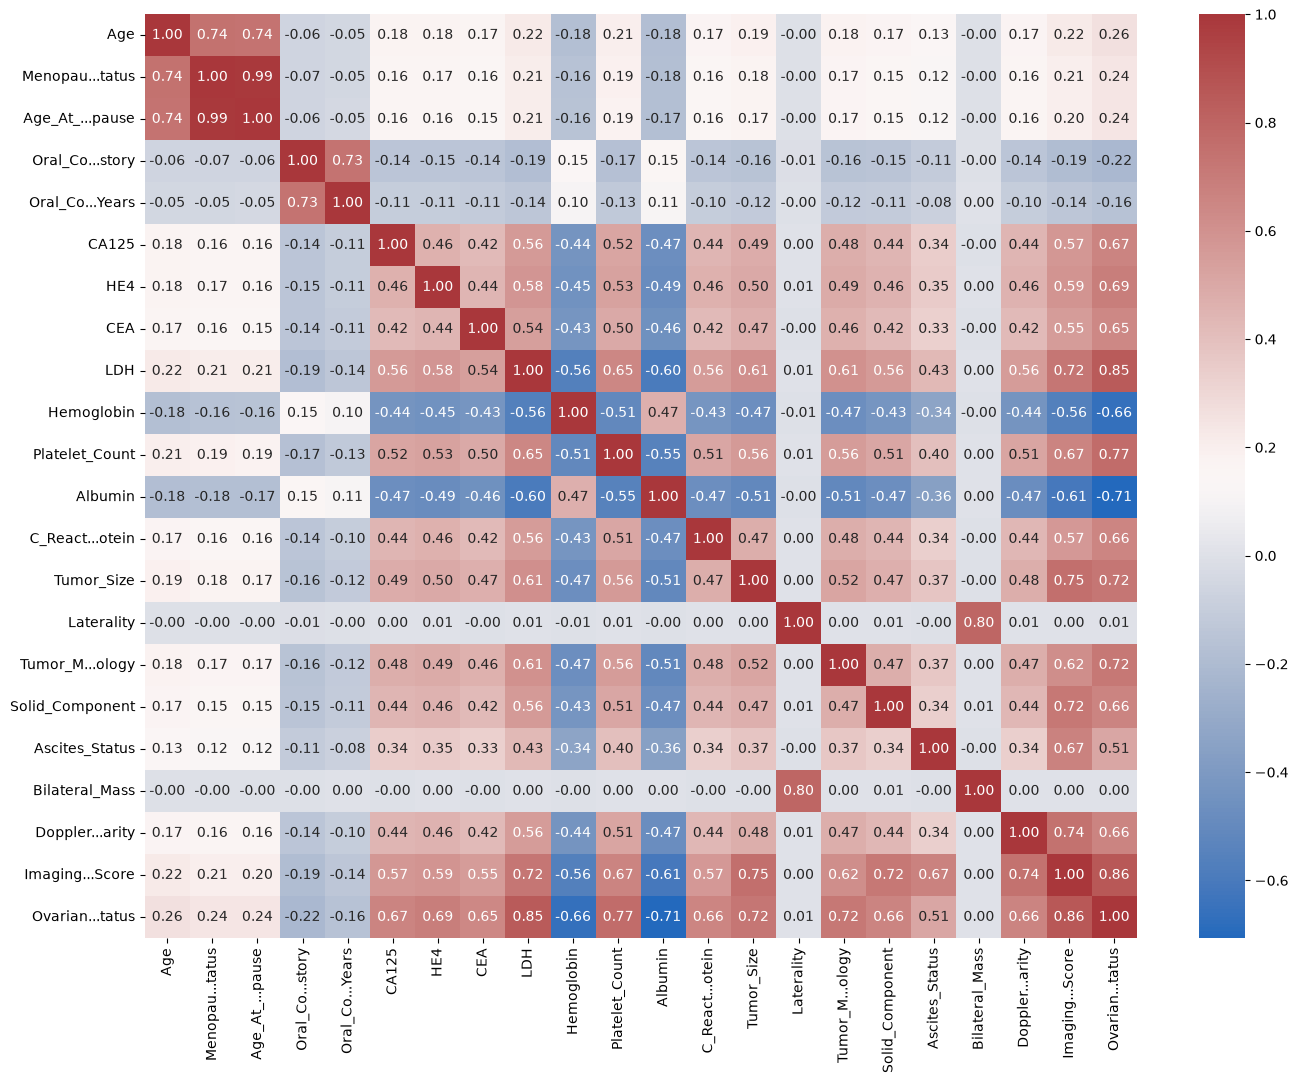

In [142]:
# HEAT MAP
corr = df[modelling_cols].corr()

strong_cols = corr.columns[(corr.abs() >= 0.6).sum() > 1]

filtered_corr = corr.loc[strong_cols, strong_cols].copy()

short_labels = [
    f"{col[:7]}...{col[-5:]}" if len(col) > 15 else col
    for col in filtered_corr.columns]
filtered_corr.index = short_labels
filtered_corr.columns = short_labels

plt.figure(figsize=(16,12))
sns.heatmap(filtered_corr, cmap="vlag", annot=True,fmt=".2f")
plt.show()

Multicollinearity (especially with Imaging Score & Target var., Biletal Mass & Laterality)

## Baseline Model

In [83]:
# train/test split
x_df = df[modelling_cols]

y_df = x_df["Ovarian_Cancer_Status"]
x_df = x_df.drop("Ovarian_Cancer_Status",axis=1)

x_df.head()

,Age,Menopausal_Status,Age_At_Menarche,Age_At_Menopause,Family_History,BRCA1_Status,BRCA2_Status,Lynch_Syndrome_Status,BMI,Parity,...,Ascites_Status,Bilateral_Mass,Papillary_Projection,Doppler_Vascularity,Lymph_Node_Enlargement,Imaging_Risk_Score,Charlson_Comorbidity_Index,ECOG_Performance_Status,Creatinine,Liver_Enzyme_Level
0,53.8,1,11.0,48.6,0,0,0,0,34.5,3,...,0,0,0,0,0,0.76,1,2,0.98,30.6
1,66.8,1,13.2,50.4,1,0,0,0,18.5,2,...,0,0,0,2,1,3.78,1,1,1.01,33.7
2,51.9,1,13.2,50.9,1,0,0,0,23.2,3,...,1,0,1,3,0,7.80,0,2,0.73,17.8
3,67.6,1,12.3,51.1,0,0,0,0,24.7,0,...,0,0,0,2,0,5.74,2,1,1.01,25.3
4,80.5,1,14.9,52.1,1,0,0,0,22.0,3,...,0,0,0,0,0,0.67,0,0,0.85,30.1


In [85]:
x_train = x_df[df.Partition == "Train"]
y_train = y_df[df.Partition == "Train"]
x_test  = x_df[df.Partition == "Validation"]
y_test  = y_df[df.Partition == "Validation"]

In [87]:
print(x_train.shape,y_train.shape,x_test.shape,y_test.shape,sep="\n")

(34946, 45)
(34946,)
(7523, 45)
(7523,)


In [89]:
x_train.isnull().sum()

Age                                     0
Menopausal_Status                       0
Age_At_Menarche                         0
Age_At_Menopause                        0
Family_History                          0
BRCA1_Status                            0
BRCA2_Status                            0
Lynch_Syndrome_Status                   0
BMI                                     0
Parity                                  0
Oral_Contraceptive_History              0
Oral_Contraceptive_Duration_Years       0
Endometriosis_History                   0
Hormone_Therapy_History                 0
Tubal_Ligation_History                  0
Abdominal_Bloating                      0
Pelvic_Pain                             0
Early_Satiety                           0
Urinary_Urgency                         0
Unexplained_Weight_Loss                 0
CA125                                1447
HE4                                  1460
CEA                                     0
CA19_9                            

In [97]:
# simple imputation

pipeline = make_pipeline(SimpleImputer(strategy='mean'), LogisticRegression())

pipeline.fit(x_train, y_train)

y_pred = pipeline.predict(x_test)


print("Accuracy :",accuracy_score(y_test,y_pred))
print("Precision:",precision_score(y_test,y_pred))
print("Recall   :",recall_score(y_test,y_pred))
print("F1 Score :",f1_score(y_test,y_pred))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


^^Perfect scores. Either data leakage or dataset is too clean

In [100]:
model = pipeline.named_steps['logisticregression']
coefs = pd.Series(model.coef_[0], index=x_train.columns)

print(coefs.abs().sort_values(ascending=False))

Hemoglobin                           1.844559
Tumor_Size                           1.160534
Age_At_Menarche                      1.115975
Imaging_Risk_Score                   1.003416
Albumin                              0.712338
CEA                                  0.541113
C_Reactive_Protein                   0.513043
Tumor_Morphology                     0.396220
Doppler_Vascularity                  0.363515
AFP                                  0.214205
ECOG_Performance_Status              0.213646
White_Blood_Cell_Count               0.202643
Abdominal_Bloating                   0.177468
Pelvic_Pain                          0.168360
Charlson_Comorbidity_Index           0.160189
Solid_Component                      0.146708
Papillary_Projection                 0.138735
Laterality                           0.129638
Parity                               0.128819
Early_Satiety                        0.126880
Ascites_Status                       0.126525
Oral_Contraceptive_Duration_Years 